# Random Forest : garder seulement les meilleurs arbres

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/MonShotData/blob/main/Machine%20Learning/Random-Forest-Meilleurs-Arbres.ipynb)

📖 **Le shot complet** : [Ton Random Forest peut être bien meilleur !](https://www.monshotdata.com/p/meilleur-random-forest)

---

Une Random Forest vote avec ses 100 arbres, mais tous ne se valent pas. L'astuce du shot : classer les arbres par précision, puis ne garder que les meilleurs. Le modèle devient beaucoup plus rapide, et sur un jeu de test sa précision monte. Ici tu refais l'expérience, puis tu vérifies si ce gain de précision est **réel** ou si c'est un effet de la façon de le mesurer.

**À la fin de ce notebook, tu sauras :**

- classer les arbres d'une forêt par précision et construire la courbe de précision cumulée ;
- créer une forêt réduite et mesurer le vrai gain de vitesse de prédiction ;
- repérer le piège de la sélection sur le jeu de test, et comment la faire proprement avec un jeu de validation.

### Avant de lancer

- **Installation** : rien : scikit-learn, NumPy, Matplotlib et Seaborn sont déjà là dans Colab et Jupyter.
- **Les données** : un jeu fictif de classification en 2 dimensions, généré par `make_classification` (graine fixée, donc les mêmes résultats à chaque exécution).
- **Durée** : environ 1 minute : la section 6 refait l'expérience sur 30 jeux de données.

🧪 *Testé le 22 novembre 2026 : exécution complète de haut en bas (Python 3.13, scikit-learn 1.8, NumPy 2.5, Matplotlib 3.11 et Seaborn 0.13). Les sorties affichées viennent de cette exécution.*

## 1. Mise en place

In [1]:
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

sns.set_theme()
colors = ['#fe7c73', '#2471A3']   # rouge pour la classe 0, bleu pour la classe 1

## 2. Le jeu de données

Deux classes qui se chevauchent (`class_sep=0.5`), 1 200 points : les 1 000 premiers servent à entraîner le modèle, les 200 derniers à le tester.

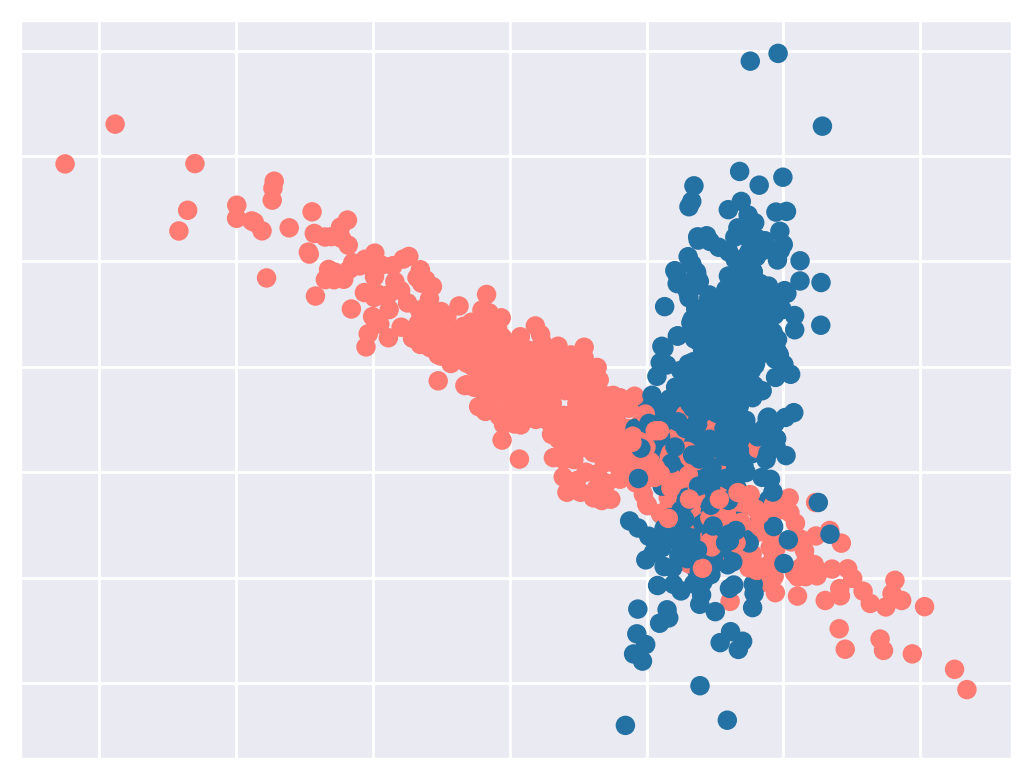

In [2]:
X, y = make_classification(
    n_samples=1200,
    n_features=2,
    n_clusters_per_class=1,
    n_informative=2,
    class_sep=0.5,
    n_redundant=0,
    n_repeated=0,
    random_state=2,
)

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in y])
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

X_train, X_test = X[:1000], X[1000:]
y_train, y_test = y[:1000], y[1000:]

## 3. La Random Forest de départ

100 arbres, chacun entraîné sur 90 % des données d'entraînement tirées au hasard (`max_samples=0.9`).

In [3]:
model = RandomForestClassifier(max_features="sqrt", max_samples=0.9, n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Précision de la forêt sur le jeu de test :", model.score(X_test, y_test))

Précision de la forêt sur le jeu de test : 0.915


## 4. L'astuce : classer les arbres, puis garder les meilleurs

Une forêt est une liste d'arbres, dans `model.estimators_`. On procède en trois temps :

1. mesurer la précision de **chaque arbre** pris seul ;
2. classer les arbres du meilleur au moins bon ;
3. pour chaque nombre `k` d'arbres, construire la forêt des `k` meilleurs et mesurer sa précision.

In [4]:
# 1. Précision de chaque arbre pris seul
precisions_arbres = np.array([arbre.score(X_test, y_test) for arbre in model.estimators_])

print(f"Meilleur arbre : {precisions_arbres.max():.3f} | moins bon arbre : {precisions_arbres.min():.3f} | moyenne : {precisions_arbres.mean():.3f}")

Meilleur arbre : 0.920 | moins bon arbre : 0.830 | moyenne : 0.882


In [5]:
# 2. Classement du meilleur au moins bon (np.argsort trie par ordre croissant, [::-1] inverse)
ordre = np.argsort(precisions_arbres)[::-1]
arbres_tries = [model.estimators_[i] for i in ordre]

In [6]:
# 3. Précision de la forêt formée des k meilleurs arbres, pour k = 2, 3, ... 99
resultats = []
for k in range(2, len(arbres_tries)):
    petite_foret = copy.copy(model)            # copie légère : le modèle d'origine n'est pas modifié
    petite_foret.estimators_ = arbres_tries[:k]
    resultats.append([k, petite_foret.score(X_test, y_test)])

resultats = np.array(resultats)

meilleur = np.argmax(resultats[:, 1])
k_optimal = int(resultats[meilleur, 0])
print(f"Meilleur nombre d'arbres : k = {k_optimal}, précision {resultats[meilleur, 1]:.3f}")

Meilleur nombre d'arbres : k = 3, précision 0.945


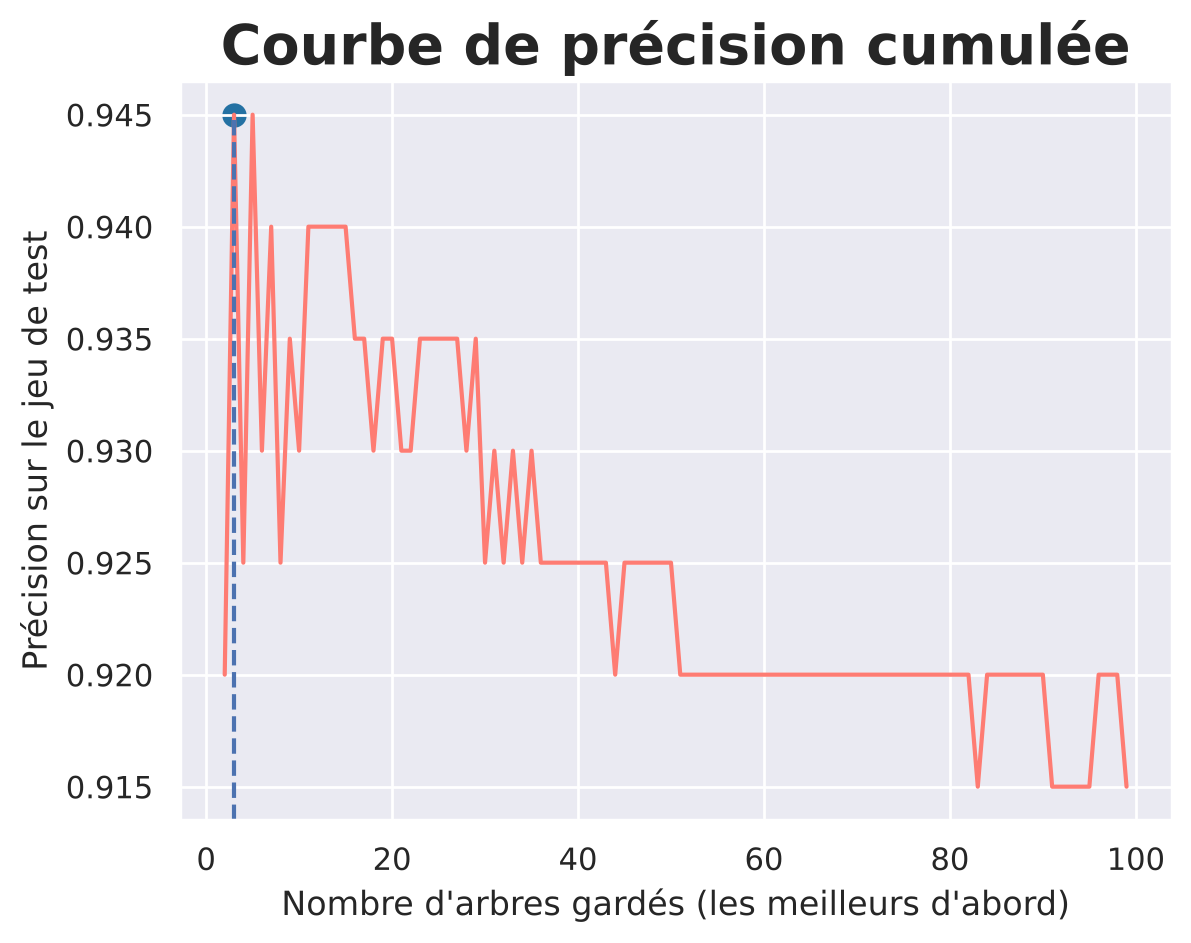

In [7]:
fig, ax = plt.subplots()
ax.plot(resultats[:, 0], resultats[:, 1], c=colors[0])
ax.axvline(x=k_optimal, ymax=0.95, ls="--")
ax.scatter([k_optimal], [resultats[meilleur, 1]], zorder=0, s=60, c=colors[1])

ax.set_title("Courbe de précision cumulée", fontsize=20, fontweight="bold")
ax.set_xlabel("Nombre d'arbres gardés (les meilleurs d'abord)")
ax.set_ylabel("Précision sur le jeu de test")
plt.show()

La courbe monte vite avec les premiers arbres, atteint un pic avec très peu d'arbres, puis redescend vers la précision de la forêt complète.

## 5. Le modèle réduit : plus rapide, et plus précis ?

In [8]:
petit_modele = copy.copy(model)
petit_modele.estimators_ = arbres_tries[:k_optimal]

print(f"Forêt complète ({len(model.estimators_)} arbres) : {model.score(X_test, y_test):.3f}")
print(f"Forêt réduite  ({len(petit_modele.estimators_)} arbres)  : {petit_modele.score(X_test, y_test):.3f}")

Forêt complète (100 arbres) : 0.915
Forêt réduite  (3 arbres)  : 0.945


Sur ce jeu de test, la forêt réduite fait mieux. Mesurons maintenant la **vitesse** de prédiction :

In [9]:
def temps_prediction(modele, X, repetitions=300):
    """Temps moyen d'un appel à predict, en millisecondes (meilleur de 5 séries)."""
    series = []
    for _ in range(5):
        debut = time.perf_counter()
        for _ in range(repetitions):
            modele.predict(X)
        series.append((time.perf_counter() - debut) / repetitions)
    return min(series) * 1000

t_complet = temps_prediction(model, X_test)
t_reduit = temps_prediction(petit_modele, X_test)

print(f"Forêt complète : {t_complet:.2f} ms")
print(f"Forêt réduite  : {t_reduit:.2f} ms")
print(f"Gain de vitesse : x{t_complet / t_reduit:.0f}")

Forêt complète : 6.35 ms
Forêt réduite  : 0.40 ms
Gain de vitesse : x16


Le gain de **vitesse** est réel et facile à comprendre : prédire avec 3 arbres coûte beaucoup moins cher que prédire avec 100. Reste la précision.

## 6. Attention : le gain de précision est-il réel ?

Regarde bien ce qu'on a fait : on a choisi **les arbres** et **le nombre d'arbres `k`** en regardant la précision sur le jeu de test, puis on a utilisé *ce même jeu de test* pour annoncer la précision finale. On a donc cherché, parmi 98 forêts possibles, celle qui se trompe le moins sur ces 200 points précis. Même si toutes les forêts étaient équivalentes, la meilleure sur ce jeu aurait l'air meilleure : c'est un biais de sélection, et la précision annoncée est **optimiste**.

La bonne méthode utilise trois jeux :

- **entraînement** : pour entraîner la forêt ;
- **validation** : pour classer les arbres et choisir `k` ;
- **test** : jamais regardé avant la fin, pour mesurer la précision réelle.

In [10]:
def reduit_foret(modele, X_sel, y_sel):
    """Classe les arbres sur (X_sel, y_sel), choisit k sur ce même jeu, renvoie la forêt réduite."""
    precisions = np.array([arbre.score(X_sel, y_sel) for arbre in modele.estimators_])
    arbres = [modele.estimators_[i] for i in np.argsort(precisions)[::-1]]

    scores = []
    for k in range(2, len(arbres)):
        f = copy.copy(modele)
        f.estimators_ = arbres[:k]
        scores.append(f.score(X_sel, y_sel))

    k = int(np.argmax(scores)) + 2
    reduite = copy.copy(modele)
    reduite.estimators_ = arbres[:k]
    return reduite, k

On répète l'expérience sur **30 jeux de données différents** (3 000 points chacun : 1 000 pour entraîner, 1 000 de validation, 1 000 de test). Pour chacun on compare deux façons de mesurer le gain de la forêt réduite par rapport à la forêt complète :

- **sélection sur le jeu de test** (ce que fait le shot) : on choisit les arbres et `k` sur le test, puis on mesure sur le test ;
- **sélection sur la validation** (méthode propre) : on choisit sur la validation, puis on mesure sur le test, qui n'a servi à rien jusque-là.

In [11]:
gains_test, gains_validation, valeurs_k = [], [], []

for graine in range(30):
    Xg, yg = make_classification(n_samples=3000, n_features=2, n_clusters_per_class=1,
                                 n_informative=2, class_sep=0.5, n_redundant=0, n_repeated=0,
                                 random_state=graine)
    X_tr, y_tr = Xg[:1000], yg[:1000]
    X_val, y_val = Xg[1000:2000], yg[1000:2000]
    X_te, y_te = Xg[2000:], yg[2000:]

    foret = RandomForestClassifier(max_features="sqrt", max_samples=0.9, n_estimators=100,
                                   random_state=42).fit(X_tr, y_tr)
    base = foret.score(X_te, y_te)

    # Sélection sur le jeu de test (biaisée)
    reduite_test, _ = reduit_foret(foret, X_te, y_te)
    gains_test.append(reduite_test.score(X_te, y_te) - base)

    # Sélection sur la validation (propre), mesure sur le test
    reduite_val, k = reduit_foret(foret, X_val, y_val)
    gains_validation.append(reduite_val.score(X_te, y_te) - base)
    valeurs_k.append(k)

gains_test = np.array(gains_test)
gains_validation = np.array(gains_validation)

print(f"Gain moyen, sélection sur le test       : {gains_test.mean() * 100:+.1f} points")
print(f"Gain moyen, sélection sur la validation : {gains_validation.mean() * 100:+.1f} points")
print(f"Jeux où la méthode propre améliore la précision : {(gains_validation > 0).sum()} sur 30, la dégrade : {(gains_validation < 0).sum()} sur 30")
print(f"Nombre d'arbres gardés (médiane) : {int(np.median(valeurs_k))}")

Gain moyen, sélection sur le test       : +1.4 points
Gain moyen, sélection sur la validation : +0.1 points
Jeux où la méthode propre améliore la précision : 15 sur 30, la dégrade : 12 sur 30
Nombre d'arbres gardés (médiane) : 11


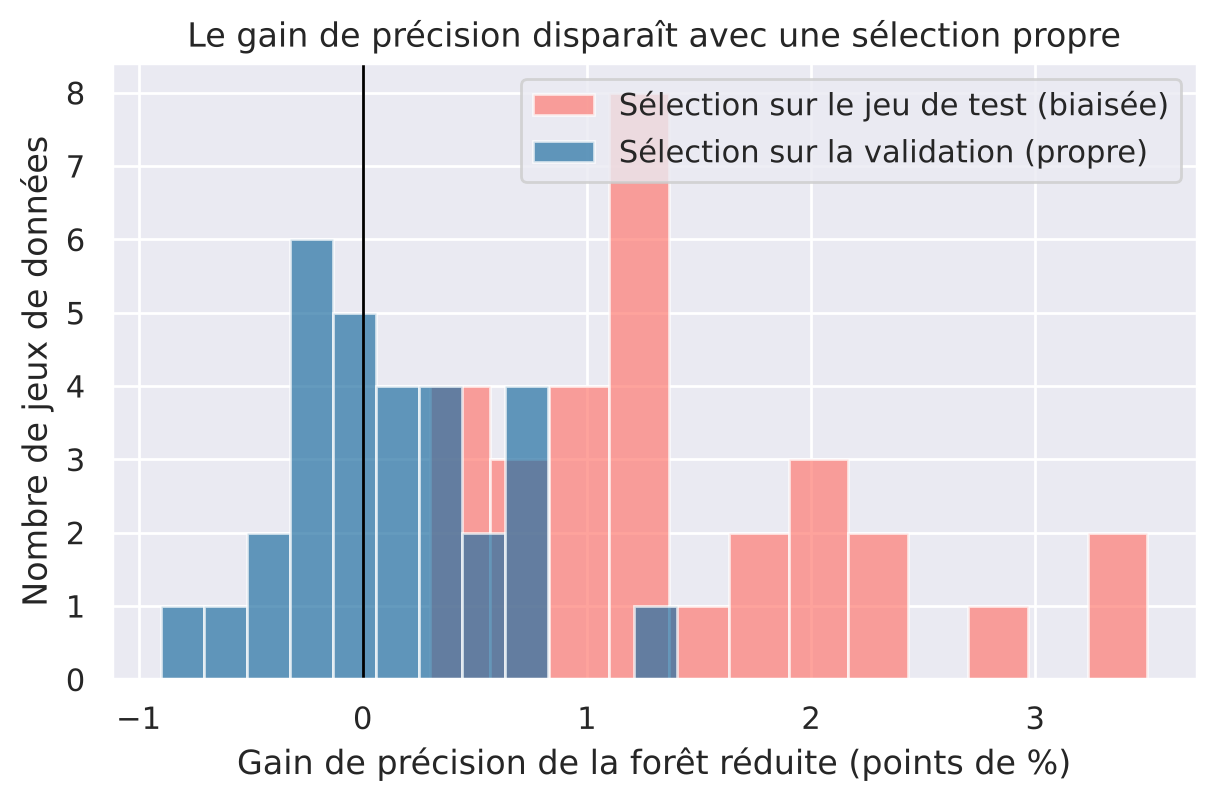

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(gains_test * 100, bins=12, alpha=0.7, color=colors[0], label="Sélection sur le jeu de test (biaisée)")
ax.hist(gains_validation * 100, bins=12, alpha=0.7, color=colors[1], label="Sélection sur la validation (propre)")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Gain de précision de la forêt réduite (points de %)")
ax.set_ylabel("Nombre de jeux de données")
ax.set_title("Le gain de précision disparaît avec une sélection propre")
ax.legend()
plt.show()

La différence est nette :

- avec la sélection sur le jeu de test, le gain est en moyenne **nettement positif**, par construction : on a pris le meilleur candidat sur ces mêmes points. Le biais est d'autant plus grand que le jeu de test est petit (ici 1 000 points ; les 200 points de la section 4 gonflent encore plus le gain) ;
- avec une sélection propre, le gain est **proche de zéro** et change de signe d'un jeu de données à l'autre : en moyenne, la forêt réduite n'est ni meilleure ni moins bonne que la forêt complète.

Le vrai bénéfice de l'astuce est donc la **vitesse** (et la taille du modèle), pas la précision.

## 7. Que faire en pratique ?

Si tu veux un modèle plus petit et plus rapide, deux approches propres :

- **réduire la forêt avec un jeu de validation**, comme dans la section 6 : tu gagnes en vitesse pour une précision équivalente **en moyenne** (elle peut varier de quelques points d'un jeu de données à l'autre) ;
- **entraîner directement moins d'arbres** (`n_estimators`) et choisir ce nombre par validation croisée.

Dans les deux cas, le jeu de test reste intact jusqu'à la mesure finale.

In [13]:
# Mesure honnête sur le premier jeu de données (section 4) : sélection sur une part de l'entraînement
X_fit, X_val_ex = X_train[:700], X_train[700:]
y_fit, y_val_ex = y_train[:700], y_train[700:]

foret_ex = RandomForestClassifier(max_features="sqrt", max_samples=0.9, n_estimators=100,
                                  random_state=42).fit(X_fit, y_fit)
reduite_ex, k_ex = reduit_foret(foret_ex, X_val_ex, y_val_ex)

print(f"Forêt complète : {foret_ex.score(X_test, y_test):.3f}")
print(f"Forêt réduite à {k_ex} arbres (choisis sur la validation) : {reduite_ex.score(X_test, y_test):.3f}")

Forêt complète : 0.920
Forêt réduite à 3 arbres (choisis sur la validation) : 0.910


Ici, la forêt réduite fait un peu moins bien que la forêt complète sur le jeu de test : avec une sélection propre, il n'y a aucun gain de précision garanti, seulement le gain de vitesse.

## 8. Ce qu'il faut retenir

- Classer les arbres d'une Random Forest par précision et ne garder que les meilleurs donne un modèle beaucoup plus rapide à prédire.
- Choisir les arbres et leur nombre sur le jeu de test, puis annoncer la précision sur ce même jeu, donne un gain de précision **biaisé** : la précision réelle est surestimée.
- Avec une sélection sur un jeu de validation et une mesure sur un jeu de test intact, le gain de précision est proche de zéro.
- Le bénéfice fiable de l'astuce est la vitesse et la taille du modèle.
- Règle générale : tout ce qui sert à choisir (arbres, hyperparamètres) ne doit jamais servir à mesurer la performance finale.

---

## Pour aller plus loin

- [Bagging et Boosting expliqués simplement (et en images)](https://www.monshotdata.com/p/bagging-et-boosting) — comment les forêts et le boosting combinent des arbres
- [Extra Trees : le secret des arbres Extra-aléatoires](https://www.monshotdata.com/p/random-forest-vs-extra-trees) — une variante plus rapide de la Random Forest
- [Tous les notebooks des shots](https://github.com/moncoachdata/MonShotData) — le code Python de la newsletter, rangé par thème